# E252 · Can unlabeled pseudo-tasks identify useful DINO updates?

**Complete** · 16 of 16 capture-disjoint walks · 32 paired draws. Functional alignment missed. Independent-bank transfer missed.

## Functional alignment

| Score on B | Spearman with semantic D | Spearman with objects | Same ordering across draws | Full selected |
| --- | --- | --- | --- | --- |
| Teacher pseudo-task | +0.42 [-0.25, +0.78] | +0.49 [-0.13, +0.78] | 93.8% | 3.1% |
| Color and texture | +0.53 [+0.07, +0.82] | +0.30 [-0.37, +0.72] | 93.8% | 9.4% |
| Teacher cosine | +0.22 [-0.28, +0.61] | +0.54 [-0.04, +0.78] | 100.0% | 0.0% |
| RankMe | +0.61 [+0.13, +0.84] | +0.55 [-0.04, +0.80] | 100.0% | 0.0% |
| Masked pixel MSE | +0.09 [-0.50, +0.58] | +0.36 [-0.29, +0.73] | 75.0% | 18.8% |

Each point is the signed full-versus-final-block advantage from the same parent and crop draw. Intervals jointly resample walks and external captures. Alignment intervals account for the two external endpoints.

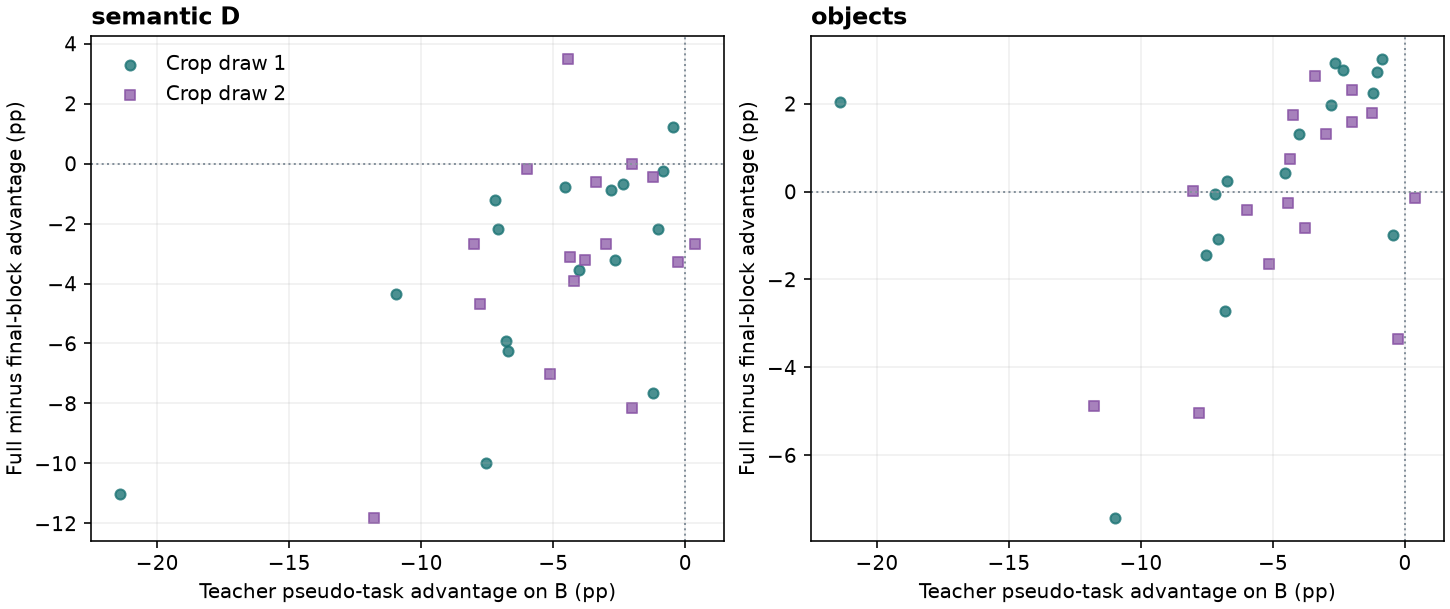

## Transfer from bank B to fresh captures and the other crop draw

| Selector on B | Evaluation | Gain vs fixed full (pp) | Gain vs fixed final-block (pp) |
| --- | --- | --- | --- |
| Teacher pseudo-task | pseudo C | +6.97 [+4.15, +9.88] | -0.10 [-0.40, +0.00] |
| Teacher pseudo-task | semantic D | +3.32 [+0.86, +5.91] | -0.11 [-0.39, +0.00] |
| Teacher pseudo-task | objects | -0.01 [-1.89, +1.82] | +0.04 [-0.03, +0.21] |
| Color and texture | pseudo C | +6.59 [+3.79, +9.53] | -0.49 [-1.34, +0.00] |
| Color and texture | semantic D | +3.41 [+1.04, +6.06] | -0.02 [-0.29, +0.24] |
| Color and texture | objects | +0.15 [-1.64, +1.88] | +0.20 [-0.06, +0.78] |
| Teacher cosine | pseudo C | +7.07 [+4.21, +9.99] | +0.00 [+0.00, +0.00] |
| Teacher cosine | semantic D | +3.43 [+0.94, +6.12] | +0.00 [+0.00, +0.00] |
| Teacher cosine | objects | -0.05 [-1.99, +1.81] | +0.00 [+0.00, +0.00] |
| RankMe | pseudo C | +7.07 [+4.21, +9.99] | +0.00 [+0.00, +0.00] |
| RankMe | semantic D | +3.43 [+0.94, +6.12] | +0.00 [+0.00, +0.00] |
| RankMe | objects | -0.05 [-1.99, +1.81] | +0.00 [+0.00, +0.00] |
| Masked pixel MSE | pseudo C | +5.69 [+3.27, +8.37] | -1.38 [-2.39, -0.53] |
| Masked pixel MSE | semantic D | +2.86 [+0.68, +5.21] | -0.58 [-1.43, +0.06] |
| Masked pixel MSE | objects | +0.14 [-1.48, +1.79] | +0.19 [-0.29, +0.76] |

The selected action is scored on the other draw, then the roles reverse. The transfer gate requires positive paired lower bounds on both C and semantic D against both fixed actions.

## Data and protocol

Frozen teacher clusters were defined on 384 earlier unlabeled captures. All encoders use the same 384-capture ridge fit bank and regularization. The pseudo-task is recovery of a frozen teacher cluster from a masked view. The reconstruction baseline measures held-out masked pixel MSE using a fixed ridge fit. The color and texture baseline uses clusters of low-level descriptors. The raw RankMe and teacher cosine baselines share bank B.

B and C contain 320 and 320 capture-disjoint queries. Semantic D has 256 fresh captures with 48 per class. The independent object panel has 272 moving-instance queries across 12 captures. C, D and object outcomes were scored after recording decisions for each walk. Each arm starts from a common 96-update last-block warmup and takes 192 matched branch updates. E252 uses the DINO ViT-S/16 checkpoint with a fixed subset of 8,192 pretrained projection prototypes in both arms. The DINO loss accumulates gradients one crop at a time to fit the Windows GPU. Transfer to E251’s ViT-B remains open. The promotion study remains conditional.

## Archived current-only versus replay pair

| Signed current-only minus replay | Difference |
| --- | --- |
| Teacher pseudo-task B | +0.00 pp |
| Teacher pseudo-task C | -0.25 pp |
| Semantic D | +0.00 pp |
| Moving-instance retrieval | +0.33 pp |

This archived ViT-S pair adds a descriptive comparison. There is one recorded training draw, and its measurements are separate from the depth gate.

In [ ]:
# Run this cell for live status. Interrupt the cell to stop watching.
import json
import time
from pathlib import Path
from IPython.display import clear_output

status_file = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\dino-e252-pseudo-utility\\results\\status.json')
while True:
    if status_file.is_file():
        info = json.loads(status_file.read_text(encoding='utf-8'))
        clear_output(wait=True)
        print(info['job'])
        print(f"{info['completed_walks']} / {info['planned_walks']} walks")
        if info.get('eta'):
            print('ETA', info['eta'])
        if info.get('error'):
            print(info['error'])
        if info['state'] in ('complete', 'failed'):
            break
    time.sleep(10)
